# Denoising Diffusion Probabilistic Models


## Question 1 - Answer

We want to find $q(x_{t-1} \mid  x_t,x_0) $, by bayes rule:
$$
q(x_{t-1} \mid x_t, x_0) = \frac{q(x_t \mid x_{t-1})q(x_{t-1} \mid x_0)}{q(x_t \mid x_0)}
$$

We know that:

$$q(x_t \mid x_{t-1}) = \mathcal{N}\left(x_t; \sqrt{1 - \beta_t}x_{t-1}, \beta_t \mathbf{I}\right)$$

$$q(x_{t-1} \mid x_0) = \mathcal{N}\left(x_{t-1}; \sqrt{\bar{\alpha}_{t-1}}x_0, (1 - \bar{\alpha}_{t-1})\mathbf{I}\right)$$

$$q(x_t \mid x_0) = \mathcal{N}\left(x_t; \sqrt{\bar{\alpha}_t}x_0, (1 - \bar{\alpha}_t)\mathbf{I}\right)$$

Since all terms are Gaussians, the product will also be Gaussian. As we can see, $q(x_{t-1} \mid  x_t,x_0) $ is proportional to the numerator, let's see what we get when we expand the terms:


$$q(x_{t-1} \mid  x_t,x_0) ∝ \exp\left(-\frac{1}{2\beta_t}\|x_t - \sqrt{1 - \beta_t}x_{t-1}\|^2\right) \times \exp\left(-\frac{1}{2(1 - \bar{\alpha}_{t-1})}\|x_{t-1} - \sqrt{\bar{\alpha}_{t-1}}x_0\|^2\right)$$

First, expand the squared norm in $q(x_t \mid x_{t-1})$:


$$\left\| x_t - \sqrt{1 - \beta_t} \, x_{t-1} \right\|^2 = \|x_t\|^2 - 2 \sqrt{1 - \beta_t} \, x_t^\top x_{t-1} + (1 - \beta_t) \|x_{t-1}\|^2$$

So:


$$-\frac{1}{2\beta_t} \left\| x_t - \sqrt{1 - \beta_t} \, x_{t-1} \right\|^2 = -\frac{1}{2\beta_t} \|x_t\|^2 + \frac{\sqrt{1 - \beta_t}}{\beta_t} x_t^\top x_{t-1} - \frac{1 - \beta_t}{2\beta_t} \|x_{t-1}\|^2$$


Similarly, expand the norm in $q(x_{t-1} \mid x_0)$:


$$\left\| x_{t-1} - \sqrt{\bar{\alpha}_{t-1}} x_0 \right\|^2 = \|x_{t-1}\|^2 - 2 \sqrt{\bar{\alpha}_{t-1}} x_{t-1}^\top x_0 + \bar{\alpha}_{t-1} \|x_0\|^2
$$

So:


$$-\frac{1}{2(1 - \bar{\alpha}_{t-1})} \left\| x_{t-1} - \sqrt{\bar{\alpha}_{t-1}} x_0 \right\|^2 = -\frac{1}{2(1 - \bar{\alpha}_{t-1})} \|x_{t-1}\|^2 + \frac{\sqrt{\bar{\alpha}_{t-1}}}{1 - \bar{\alpha}_{t-1}} x_{t-1}^\top x_0 - \frac{\bar{\alpha}_{t-1}}{2(1 - \bar{\alpha}_{t-1})} \|x_0\|^2
$$

Collect the quadratic form in $x_{t-1}$:

The quadratic term:


$$-\frac{1 - \beta_t}{2\beta_t} \|x_{t-1}\|^2 - \frac{1}{2(1 - \bar{\alpha}_{t-1})} \|x_{t-1}\|^2
= -\frac{1}{2} \left( \frac{1 - \beta_t}{\beta_t} + \frac{1}{1 - \bar{\alpha}_{t-1}} \right) \|x_{t-1}\|^2
$$

The linear term:


$$\frac{\sqrt{1 - \beta_t}}{\beta_t} x_t^\top x_{t-1} + \frac{\sqrt{\bar{\alpha}_{t-1}}}{1 - \bar{\alpha}_{t-1}} x_0^\top x_{t-1}
= \left( \frac{\sqrt{1 - \beta_t}}{\beta_t} x_t + \frac{\sqrt{\bar{\alpha}_{t-1}}}{1 - \bar{\alpha}_{t-1}} x_0 \right)^\top x_{t-1}
$$

And we can discard the constant term. So, now we have the quadratic form:

$$
-\frac{1}{2}x_{t-1}^T A x_{t-1} + b^T x_{t-1} + \text{const}
$$

where:

$$
A = \frac{1 - \beta_t}{\beta_t}\mathbf{I} + \frac{1}{1 - \bar{\alpha}_{t-1}}\mathbf{I}
$$

$$
b = \left( \frac{\sqrt{1 - \beta_t}}{\beta_t} x_t + \frac{\sqrt{\bar{\alpha}_{t-1}}}{1 - \bar{\alpha}_{t-1}} x_0 \right)
$$

The resulting Gaussian has (learned this in the class):

$$
\Sigma = A^{-1}, \quad \mu = \Sigma b
$$

To compute $\Sigma$, we will use the identity $α_t = 1 - β_t$:

$$
\bar{\alpha}_t = \bar{\alpha}_{t-1}(1 - \beta_t)
$$

So:

$$
1 - \bar{\alpha}_t = 1 - \bar{\alpha}_{t-1}(1 - \beta_t) = 1 - \bar{\alpha}_{t-1} + \bar{\alpha}_{t-1}\beta_t
$$

Simplify $\Sigma$:

$$
\boxed{ \Sigma = \left( \frac{1 - \beta_t}{\beta_t} + \frac{1}{1 - \bar{\alpha}_{t-1}} \right)^{-1} = \left(\frac{1 - \bar{\alpha}_{t-1} + \bar{\alpha}_{t-1}\beta_t}{\beta_t(1 - \bar{\alpha}_{t-1})}\right)^{-1}=\frac{\beta_t(1 - \bar{\alpha}_{t-1})}{1 - \bar{\alpha}_t}
}$$

Now let's do $μ$:

\begin{aligned}
\mu &= \Sigma \left( \frac{\sqrt{1 - \beta_t}}{\beta_t} x_t + \frac{\sqrt{\bar{\alpha}_{t-1}}}{1 - \bar{\alpha}_{t-1}} x_0 \right) \\
&= \Sigma \left( \frac{(1 - \beta_t)}{\beta_t} \cdot \frac{x_t}{\sqrt{1 - \beta_t}} + \frac{1}{1 - \bar{\alpha}_{t-1}} \cdot \sqrt{\bar{\alpha}_{t-1}}x_0 \right) \\
&= \frac{\beta_t(1 - \bar{\alpha}_{t-1})}{1 - \bar{\alpha}_t} \left( \frac{(1 - \beta_t)}{\beta_t} \cdot \frac{x_t}{\sqrt{1 - \beta_t}} + \frac{1}{1 - \bar{\alpha}_{t-1}} \cdot \sqrt{\bar{\alpha}_{t-1}}x_0 \right) \\
&= \frac{(1 - \bar{\alpha}_{t-1})(1 - \beta_t)}{1 - \bar{\alpha}_t} \cdot \frac{x_t}{\sqrt{1 - \beta_t}} + \frac{\beta_t \sqrt{\bar{\alpha}_{t-1}}}{1 - \bar{\alpha}_t}x_0 \\
&= \boxed{\frac{\sqrt{1 - \beta_t}(1 - \bar{\alpha}_{t-1})}{1 - \bar{\alpha}_t}x_t + \frac{\sqrt{\bar{\alpha}_{t-1}}\beta_t}{1 - \bar{\alpha}_t}x_0}
\end{aligned}

Since we found the mean and variance, we can put everything together and finally get:

$$q(x_{t-1} \mid  x_t,x_0) = \mathcal{N}\left(x_{t-1}; \mu, Σ\right) $$

In our case:

$$\tilde{\beta_t} = \Sigma$$
$$\tilde{\mu_t} = \mu$$

## Configurations and initializations

This section loads libraries and configurations for various tasks for this course

In [ ]:
## Standard libraries
import os
import math
import numpy as np
import pandas as pd
from collections import defaultdict

## Imports for plotting
import matplotlib.pyplot as plt
plt.set_cmap('cividis')
import seaborn as sns

## Progress bar
from tqdm.notebook import tqdm

## PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torch.optim as optim
# Torchvision
import torchvision
from torchvision.datasets import MNIST
from torchvision import transforms

# Path to the folder where the datasets are/should be downloaded (e.g. MNIST)
DATASET_PATH = "../data"

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Fetching the device that will be used throughout this notebook
device = torch.device("cpu") if not torch.cuda.is_available() else torch.device("cuda")
print("Using device", device)

Using device cuda


<Figure size 640x480 with 0 Axes>

In [ ]:
def scale(sample):
    return 2 * sample - 1

# Transformations applied on each image => only make them a tensor
transform = transforms.Compose([transforms.ToTensor(), scale])

# Loading the training dataset. We need to split it into a training and validation part
train_dataset = MNIST(root=DATASET_PATH, train=True, transform=transform, download=True)

train_set, val_set = torch.utils.data.random_split(train_dataset, [50000, 10000])

# Loading the test set
test_set = MNIST(root=DATASET_PATH, train=False, transform=transform, download=True)

# We define a set of data loaders that we can use for various purposes later.
train_loader = data.DataLoader(train_set, batch_size=128, shuffle=True,  drop_last=True)
val_loader   = data.DataLoader(val_set,   batch_size=128, shuffle=False, drop_last=True)
test_loader  = data.DataLoader(test_set,  batch_size=128, shuffle=False, drop_last=True)

print('Train size:', len(train_loader.dataset))
print('Validation size:', len(val_loader.dataset))
print('Test size:', len(test_loader.dataset))

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.11MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 134kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.27MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.15MB/s]

Train size: 50000
Validation size: 10000
Test size: 10000


In [ ]:
def show_tensor_image(img):
    reverse_transforms = transforms.Compose([
        transforms.Lambda(lambda t: (t + 1) / 2),
        transforms.Lambda(lambda t: torch.minimum(torch.tensor([1]), t)),
        transforms.Lambda(lambda t: torch.maximum(torch.tensor([0]), t)),
        transforms.ToPILImage(),
    ])
    plt.imshow(reverse_transforms(img))

In [ ]:
def show_imgs(imgs, nrows=1):
    ncols = len(imgs) // nrows

    imgs = torch.stack(imgs) if isinstance(imgs, list) else imgs        # T, img, ch, size, size or img, ch, size, size

    imgs = imgs.unsqueeze(0) if imgs.ndim == 4 else imgs                # T, img, ch, size, size
    imgs = imgs.transpose(1, 0)                                         # img, T, ch, size, size
    imgs = imgs.reshape((-1,) + imgs.shape[2:])                         # img * T, ch, size, size

    plt.figure(figsize=(ncols * 1.2, nrows * 1.2))
    grid = torchvision.utils.make_grid(imgs.cpu(), nrow=ncols, pad_value=128)
    show_tensor_image(grid.detach().cpu())

    plt.axis('off')
    plt.show()
    plt.close()


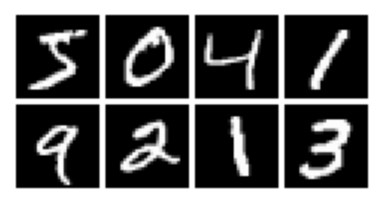

In [ ]:
show_imgs([train_dataset[i][0] for i in range(8)], nrows=2)

## Components & Architecture

In [ ]:
class EmbedBlock(nn.Module):
    def __init__(self, input_dim, emb_dim):
        super(EmbedBlock, self).__init__()
        self.input_dim = input_dim
        layers = [
            nn.Linear(input_dim, emb_dim),
            nn.ReLU(),
            nn.Linear(emb_dim, emb_dim),
            nn.Unflatten(1, (emb_dim, 1, 1)), # Reverted Unflatten layer
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(-1, self.input_dim)
        return self.model(x)

class SinusoidalPositionEmbedBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

# Double Conv + maxpool
class DownBlock(nn.Module):
    def __init__(self, in_chs, out_chs):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(in_chs, out_chs, 3, 1, 1),
            nn.BatchNorm2d(out_chs),
            nn.ReLU(),
            nn.Conv2d(out_chs, out_chs, 3, 1, 1),
            nn.BatchNorm2d(out_chs),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

    def forward(self, x):
        return self.model(x)

class UpBlock(nn.Module):
    def __init__(self, in_chs, out_chs):
        super().__init__()
        self.model = nn.Sequential(
            nn.ConvTranspose2d(2 * in_chs, out_chs, 3, 2, 1, 1),
            nn.BatchNorm2d(out_chs),
            nn.ReLU(),
            nn.Conv2d(out_chs, out_chs, 3, 1, 1),
            nn.BatchNorm2d(out_chs),
            nn.ReLU()
        )

    def forward(self, x, skip):
        x = torch.cat((x, skip), 1)
        x = self.model(x)
        return x


<img align="center" width="70%" src="https://sharon.srworkspace.com/dgm/time.png"/>

In [ ]:
class UNet(nn.Module):
    def __init__(self, T, img_shape):
        super(UNet, self).__init__()
        self.T = T

        img_chs = img_shape[0]
        down_chs = (64, 128, 128)
        up_chs = down_chs[::-1]               # Reverse of the down channels
        # Calculate latent_image_size based on the input image height and the downsampling factors
        latent_image_size = img_shape[1] // (2 ** (len(down_chs) -1)) # Corrected calculation

        # New
        t_embed_dim = 8

        # Inital convolution
        self.down0 = nn.Sequential(
            nn.Conv2d(img_chs, down_chs[0], 3, padding=1),
            nn.BatchNorm2d(down_chs[0]),
            nn.ReLU()
        )

        # Downsample
        self.down1 = DownBlock(down_chs[0], down_chs[1])
        self.down2 = DownBlock(down_chs[1], down_chs[2])
        self.to_vec = nn.Sequential(nn.Flatten(), nn.ReLU())

        # Embeddings
        self.dense_emb = nn.Sequential(
            nn.Linear(down_chs[2]*latent_image_size**2, down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[2]*latent_image_size**2),
            nn.ReLU()
        )
        self.sinusoidaltime = SinusoidalPositionEmbedBlock(t_embed_dim) # New
        self.temb_1 = EmbedBlock(t_embed_dim, up_chs[0]) # New
        self.temb_2 = EmbedBlock(t_embed_dim, up_chs[1]) # New

        # Upsample
        self.up0 = nn.Sequential(
            nn.Unflatten(1, (up_chs[0], latent_image_size, latent_image_size)),
            nn.Conv2d(up_chs[0], up_chs[0], 3, padding=1),
            nn.BatchNorm2d(up_chs[0]),
            nn.ReLU(),
        )
        self.up1 = UpBlock(up_chs[0], up_chs[1]) # 128, 128
        self.up2 = UpBlock(up_chs[1], up_chs[2]) # 128, 64

        # Match output channels
        self.out = nn.Sequential(
            nn.Conv2d(2 * up_chs[-1], up_chs[-1], 3, 1, 1),
            nn.BatchNorm2d(up_chs[-1]),
            nn.ReLU(),
            nn.Conv2d(up_chs[-1], img_chs, 3, 1, 1)
        )

    def forward(self, x, t):
        # Convert t to range [0,1] and get time embedding
        t = t.float() / self.T  # Normalize time step

        # ---- Downsampling ----
        x0 = self.down0(x)     # No downsampling
        x1 = self.down1(x0)    # /2
        x2 = self.down2(x1)    # /2 again => /4

        # ---- Bottleneck ----
        vec = self.to_vec(x2)
        vec = self.dense_emb(vec)

        # ---- Time embeddings ----
        temb = self.sinusoidaltime(t)  # [B, t_embed_dim]
        t1 = self.temb_1(temb)         # [B, up_chs[0], 1, 1]
        t2 = self.temb_2(temb)         # [B, up_chs[1], 1, 1]


        # ---- Upsampling ----
        up = self.up0(vec)             # up shape: [B, up_chs[0], H, W]
        up = up + t1                   # Add t1 to feature map (broadcasted)

        up = self.up1(up, x2)          # up shape: [B, up_chs[1], H*2, W*2]
        up = up + t2                   # Add t2 after upsampling

        up = self.up2(up, x1)          # final skip connection

        # ---- Output ----
        out = self.out(torch.cat((up, x0), dim=1))
        return out

## Define DDPM model

A fundemantal idea of diffusion models is to add a little noise to the image each time step and learn how to remove it, depending on time. Here, we will use different variance schedules of  $\beta_t$.

<img width="70%" src="https://sharon.srworkspace.com/dgm/dog.png"/>

In [ ]:
class DDPM(nn.Module):
    def __init__(self, T, img_shape, method='cosine'):
        super(DDPM, self).__init__()
        self.T = T

        epsilon=0.008
        if method == 'cosine':
            steps=torch.linspace(0,T,steps=T+1).to(device)
            f_t=torch.cos(((steps/T+epsilon)/(1.0+epsilon))*math.pi*0.5)**2
            self.Beta = torch.clip(1.0-f_t[1:]/f_t[:T], 0.0, 0.999)

        elif method == 'linear':
            self.Beta = torch.linspace(1e-4, 2e-2, T).to(device)

        # Forward diffusion variables
        self.a = 1.0 - self.Beta
        self.a_bar = torch.cumprod(self.a, dim=0)

        self.img_chs = img_shape[0]
        self.img_size = img_shape[1]

        self.net = UNet(T, img_shape)

        # Logging
        self.logs = defaultdict(list)

    def log(self, key, value):
        self.logs[key].append(value)

    def q(self, x_0, t):
        """
        Samples a new image from q
        Returns a tuple (img_after_noise, noise) at timestep t
        x_0: the original image
        t: timestep
        """
        noise = torch.randn_like(x_0).to(device)
        a_bar_t = self.a_bar[t].view(-1, 1, 1, 1)
        x_t = torch.sqrt(a_bar_t) * x_0 + torch.sqrt(1 - a_bar_t) * noise
        return x_t, noise

    # To be used later
    def get_x0_pred(self, x_t, t, e_t):
      a_bar_t = self.a_bar[t].view(-1, 1, 1, 1)  # Expand for broadcasting
      x_0_pred = (x_t - torch.sqrt(1 - a_bar_t) * e_t) / torch.sqrt(a_bar_t)
      x_0_pred.clamp_(-1, 1)
      return x_0_pred


    @torch.no_grad()
    def reverse_q(self, x_t, t, e_t):
        """
        Samples a new image from p
        Returns a tuple (img_before_noise) at timestep t
        x_t: the noisy image
        t: timestep
        e_t: predicted noise
        """
        a_t = self.a[t].view(-1, 1, 1, 1)
        a_bar_t = self.a_bar[t].view(-1, 1, 1, 1)
        b_t = self.Beta[t].view(-1, 1, 1, 1)
        z = torch.randn_like(x_t).to(device) * (t > 0).float().view(-1, 1, 1, 1)

        x_t_minus_1 = (1 / torch.sqrt(a_t)) * (x_t - b_t / torch.sqrt(1 - a_bar_t) * e_t) + torch.sqrt(b_t) * z
        return x_t_minus_1

    def get_loss(self, x_0, t):
        """
        Returns the loss between the true noise and the predicted noise
        x_0: the original image
        t: timestep
        """
        x_t, noise = self.q(x_0, t)
        e_t = self.net(x_t, t)
        loss = F.mse_loss(e_t, noise)
        return loss

    @torch.no_grad()
    def sample(self, num_imgs=1, skip=1):
      self.eval()

      x_t = torch.randn(num_imgs, self.img_chs, self.img_size, self.img_size).to(device)
      output = []

      for t in reversed(range(self.T)):
          t_batch = torch.full((num_imgs,), t, dtype=torch.long, device=device)
          e_t = self.net(x_t, t_batch)               # Predict noise
          x_t = self.reverse_q(x_t, t_batch, e_t)    # Denoise one step
          output.append(x_t.clone())                 # Save the current step (optional)

      return torch.stack(output)[::skip]  # shape: (T//skip, B, C, H, W)

    def log(self, key, value):
        self.logs[key].append(value)

    def training_step(self, batch):
        t = torch.randint(0, self.T, (len(batch),), device=device)
        loss = self.get_loss(batch, t)

        # Log losses
        self.log('train_loss', loss.item())
        return loss

    @torch.no_grad()
    def validation_step(self, loader):
        loss = 0
        for imgs, _ in tqdm(loader, leave=False):
          imgs = imgs.to(device)
          t = torch.randint(0, self.T, (len(imgs),), device=device)
          loss += self.get_loss(imgs, t)

        loss = loss.item()
        loss = loss / len(loader)
        # Log losses
        self.log('val_loss', loss)
        return loss

    @torch.no_grad()
    def test_step(self, loader):
        loss = 0
        for imgs, _ in tqdm(loader, leave=False):
          imgs = imgs.to(device)
          t = torch.randint(0, self.T, (len(imgs),), device=device)
          loss += self.get_loss(imgs, t)

        loss = loss.item()
        loss = loss / len(loader)
        # Log losses
        self.log('test_loss', loss)
        return loss

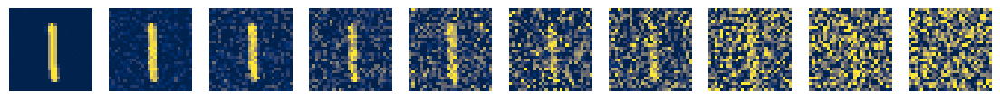

In [ ]:
#@title you may run this to make sure your implementation for q is good

x_0 = train_set[1][0].to(device)  # Initial image
plt.figure(figsize=(14, 8))

ddpm = DDPM(T=1000, img_shape=x_0.shape)

for t in range(1000):
    t_tenser = torch.Tensor([t]).type(torch.int64)
    x_t, noise = ddpm.q(x_0, t_tenser)
    img = torch.squeeze(x_t).cpu()
    if t % 100 == 0:
      ax = plt.subplot(1, 10, t // 100 + 1)
      ax.axis('off')
      show_tensor_image(img)

## Train

In [ ]:
from torchsummary import summary

img_shape = train_set[0][0].shape
model = DDPM(T=1000, img_shape=img_shape)
print("Num params: {:,}".format(sum(p.numel() for p in model.parameters())))
model = torch.compile(model.to(device))
model = model.to(device)


optimizer = optim.Adam(model.parameters(), lr=1e-3)
epochs = 25

Num params: 3,032,449


  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 0 | Validation Loss: 0.07215493764632787 


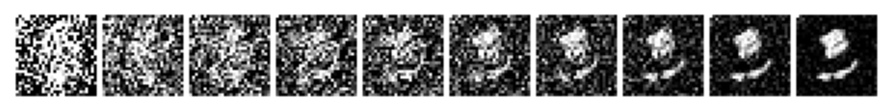

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 1 | Validation Loss: 0.06488328102307442 


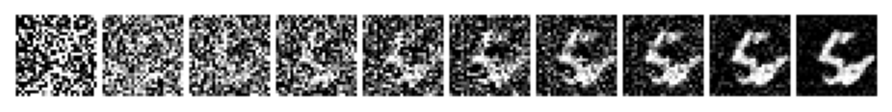

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 2 | Validation Loss: 0.058745274176964395 


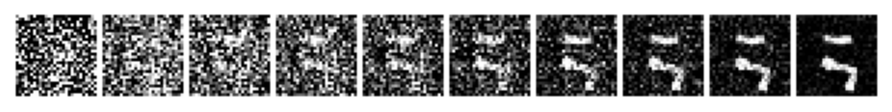

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 3 | Validation Loss: 0.05733184325389373 


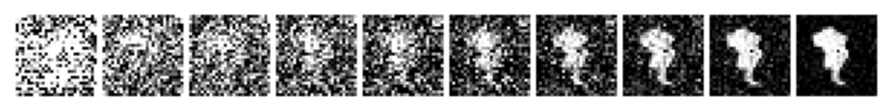

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 4 | Validation Loss: 0.05301808088253706 


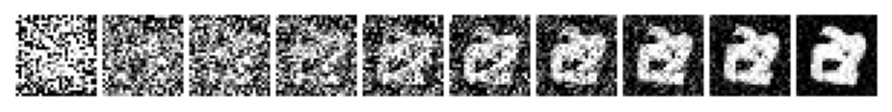

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 5 | Validation Loss: 0.04939440274849916 


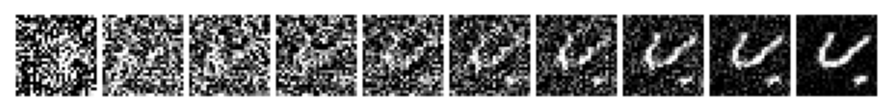

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 6 | Validation Loss: 0.049080671408237554 


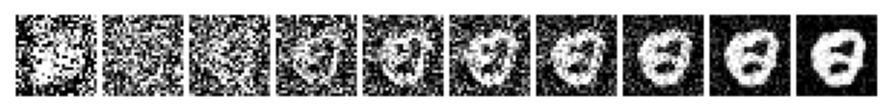

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 7 | Validation Loss: 0.048664355889344826 


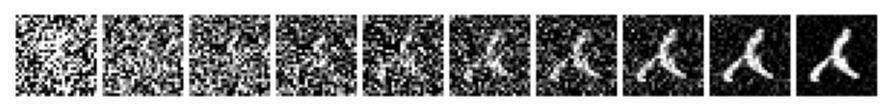

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 8 | Validation Loss: 0.048737574846316606 


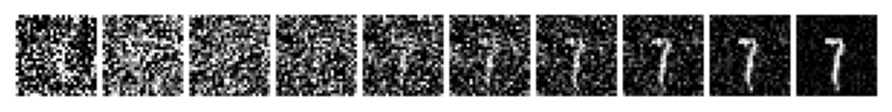

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 9 | Validation Loss: 0.04556577633588742 


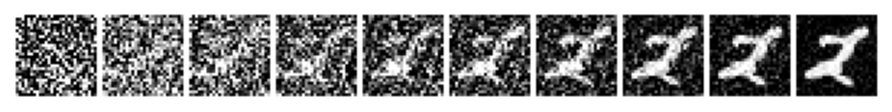

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 10 | Validation Loss: 0.045802914179288425 


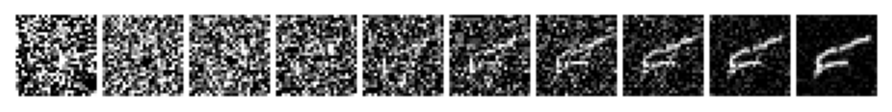

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 11 | Validation Loss: 0.044654072859348394 


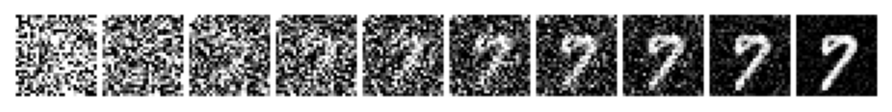

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 12 | Validation Loss: 0.04400033217210036 


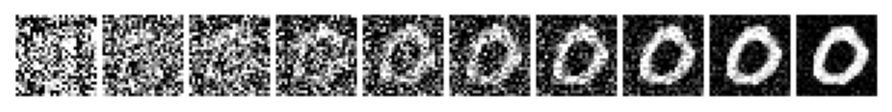

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 13 | Validation Loss: 0.0438385009765625 


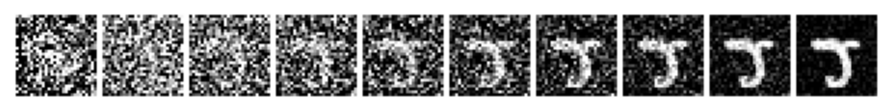

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 14 | Validation Loss: 0.04404895122234638 


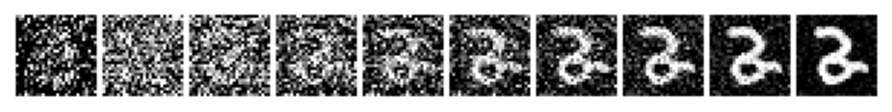

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 15 | Validation Loss: 0.04310528437296549 


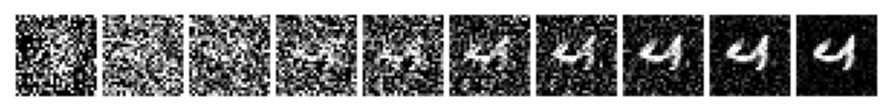

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 16 | Validation Loss: 0.04249109366001227 


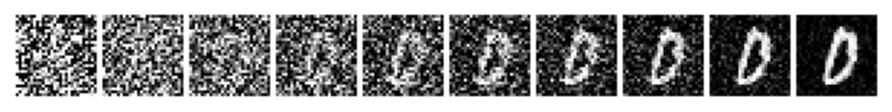

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 17 | Validation Loss: 0.04255495315943009 


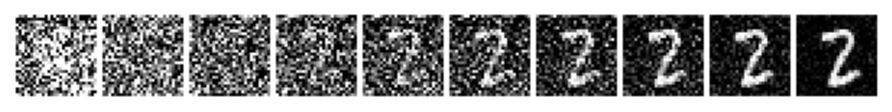

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 18 | Validation Loss: 0.042562438891484186 


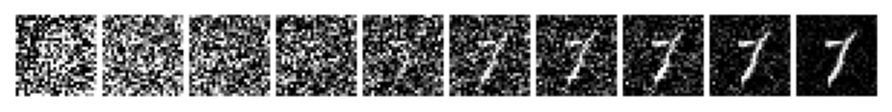

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 19 | Validation Loss: 0.04206422353402162 


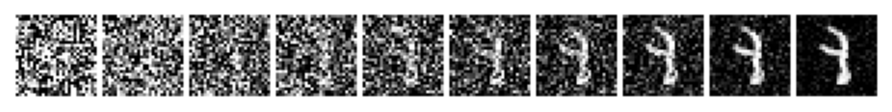

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 20 | Validation Loss: 0.04313742503141745 


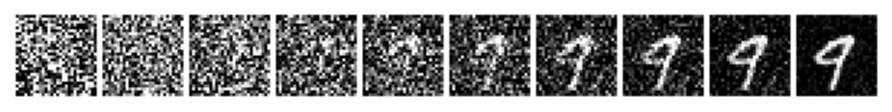

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 21 | Validation Loss: 0.0427699394715138 


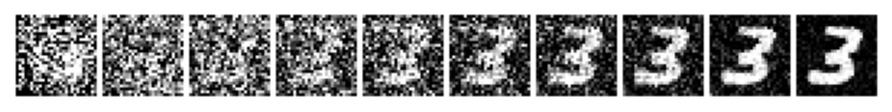

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 22 | Validation Loss: 0.04234591814187857 


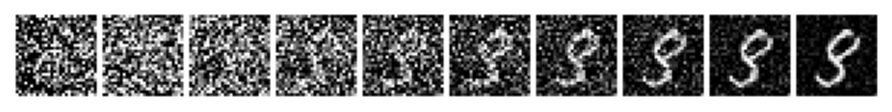

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 23 | Validation Loss: 0.04131679962842892 


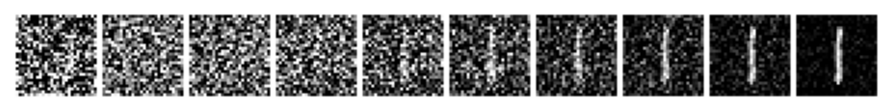

  0%|          | 0/390 [00:00<?, ?it/s]

  0%|          | 0/78 [00:00<?, ?it/s]

Epoch 24 | Validation Loss: 0.04154818791609544 


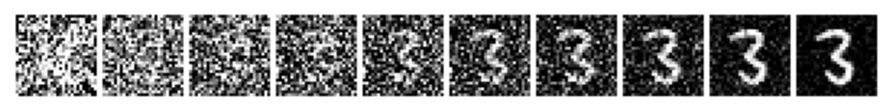

  0%|          | 0/78 [00:00<?, ?it/s]

Final test loss: 0.04176465058938051


In [ ]:
# Training loop
for epoch in range(epochs):
    model.train()
    #losses = [] # No longer need this intermediate list

    for imgs, _ in tqdm(train_loader):
        imgs = imgs.to(device)
        optimizer.zero_grad()
        loss = model.training_step(imgs)
        #losses.append(loss.item()) # Append batch loss - append directly to logs
        model.log('train_loss', loss.item()) # Log individual batch loss
        loss.backward()
        optimizer.step()

    # Log average training loss for the epoch - no longer needed here, logged per batch
    # model.log('train_loss', losses)

    val_loss = model.validation_step(val_loader)

    if epoch % 1 == 0:
        print(f"Epoch {epoch} | Validation Loss: {val_loss} ") # Corrected print statement
        sampled_data = model.sample(skip=100)
        show_imgs(sampled_data)

# Test loop
model.eval()

final_loss = model.test_step(test_loader)
print(f"Final test loss: {final_loss}")

# Save the model
torch.save(model.state_dict(), 'mnist.pth')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_loss(ddpm_model, epochs):
    # Calculate average training loss per epoch
    train_losses = ddpm_model.logs['train_loss']
    batch_size = len(train_loader)
    # Ensure train_losses is treated as a flat list of all batch losses
    flat_train_losses = []
    for l in train_losses:
        if isinstance(l, list):
            flat_train_losses.extend(l)
        else:
            flat_train_losses.append(l)

    train_loss_per_epoch = []
    for i in range(epochs):
        start_index = i * batch_size
        end_index = (i + 1) * batch_size
        if end_index <= len(flat_train_losses):
            train_loss_per_epoch.append(np.mean(flat_train_losses[start_index:end_index]))
        else:
            # Handle cases where the last epoch might not have a full batch
            train_loss_per_epoch.append(np.mean(flat_train_losses[start_index:]))
            break # Stop if we've processed all available training losses


    val_losses = []
    for l in ddpm_model.logs['val_loss']:
        if isinstance(l, list):
            val_losses.append(np.mean(l)) # Take mean if it's a list
        else:
            val_losses.append(float(l)) # Convert to float if it's a scalar


    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(train_loss_per_epoch) + 1), train_loss_per_epoch, label='Training Loss')
    plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

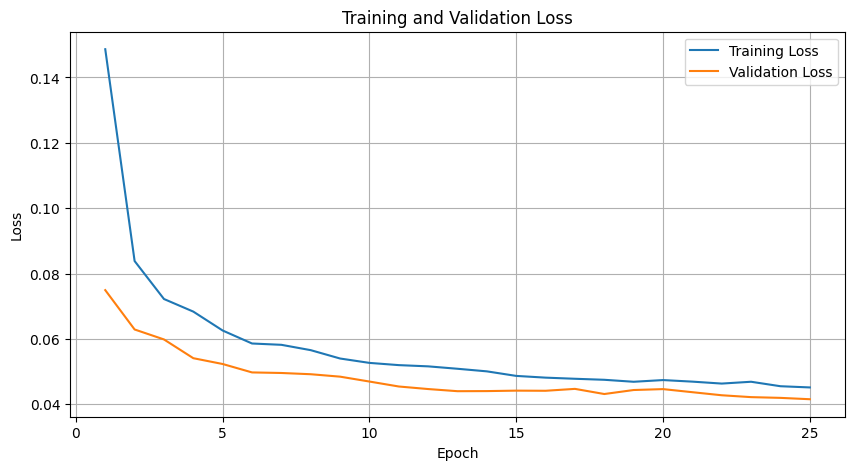

In [ ]:
# plot
plot_loss(model, epochs)

In [ ]:
def show_samples(ddpm_model, num_samples=8):
    samples = ddpm_model.sample(num_imgs=num_samples, skip=100)  # (T/skip, B, C, H, W)
    final_imgs = samples[-1]  # final step: shape (B, C, H, W)

    # Plot
    grid_rows = 2
    grid_cols = num_samples // grid_rows
    plt.figure(figsize=(grid_cols * 2, grid_rows * 2))
    for i in range(num_samples):
        plt.subplot(grid_rows, grid_cols, i + 1)
        plt.imshow(imgs[i].permute(1, 2, 0).cpu().numpy())
        plt.axis('off')
    plt.suptitle('Generated Samples')
    plt.tight_layout()
    plt.show()

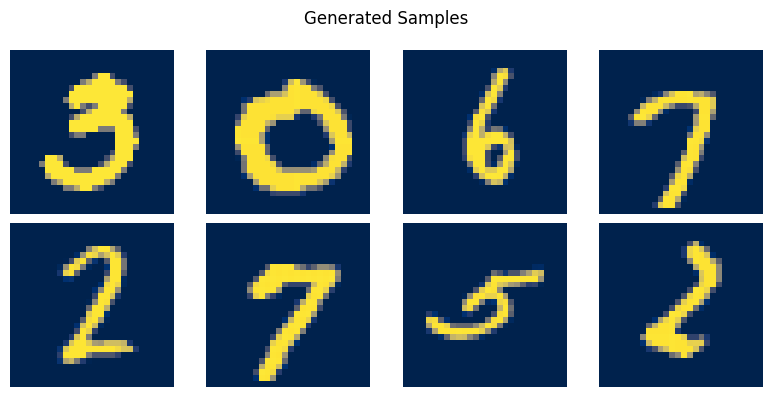

In [ ]:
# plot samples
show_samples(model)

## Autocomplete two images

In [ ]:
def create_half_mask(images, mode='bottom'):
    # images: (B, C, H, W)
    B, C, H, W = images.shape
    mask = torch.ones_like(images).to(device)
    if mode == 'bottom':
        mask[:, :, H//2:, :] = 0
    elif mode == 'top':
        mask[:, :, :H//2, :] = 0
    return mask


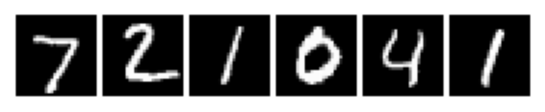

In [ ]:
# plot the images
images = next(iter(test_loader))[0].to(device)[:6]  # Get 6 images
show_imgs(images)

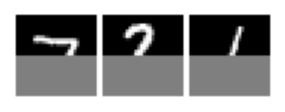

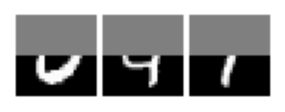

In [ ]:
# plot the visible halves
bottom_mask = create_half_mask(images[:3], mode='bottom')

# masked images
show_imgs(images[:3] * bottom_mask)

top_mask = create_half_mask(images[3:], mode='top')
show_imgs(images[3:] * top_mask)

In [ ]:
@torch.no_grad()
def complete_image(model, y, ymask, num_imgs=1, resample_steps=None):
    """
    Image completion using the 'stamping' method described in the document.

    Args:
        y: The original partial image (B, C, H, W), values in [-1, 1].
        ymask: Binary mask (1 where y is known, 0 where unknown).
        num_imgs: Number of samples to generate.
        resample_steps: Optional list of (t, j) tuples for back-and-forth resampling.

    Returns:
        Completed images of shape (B, C, H, W)
    """

    model.eval()
    B, C, H, W = y.shape
    x_t = torch.randn(B, C, H, W).to(device)

    # Precompute the noisy versions of y at all timesteps
    y_noisy = []
    for t in reversed(range(model.T)):
        t_batch = torch.full((B,), t, dtype=torch.long, device=device)
        y_t, _ = model.q(y, t_batch)  # Noisy version of the known half
        y_noisy.append(y_t)

    for t in reversed(range(model.T)):
        t_batch = torch.full((B,), t, dtype=torch.long, device=device)

        e_t = model.net(x_t, t_batch)
        x_0_pred = model.get_x0_pred(x_t, t_batch, e_t)

        # Reverse step (mean of x_{t-1})
        a_t = model.a[t].view(-1, 1, 1, 1)
        a_bar_t = model.a_bar[t].view(-1, 1, 1, 1)
        b_t = model.Beta[t].view(-1, 1, 1, 1)

        mean_xt_minus_1 = (1 / torch.sqrt(a_t)) * (x_t - b_t / torch.sqrt(1 - a_bar_t) * e_t)

        # Stamp the known region back using y_noisy[t-1]
        if t > 0:
            mean_xt_minus_1 = y_noisy[t-1] * ymask + mean_xt_minus_1 * (1 - ymask)

        # Sample x_{t-1}
        z = torch.randn_like(x_t).to(device) if t > 0 else 0
        x_t = mean_xt_minus_1 + torch.sqrt(b_t) * z

        # Optional resampling (back-and-forth to t+j for better boundary blending)
        if resample_steps is not None:
            for (t_resample, j) in resample_steps:
                if t == t_resample:
                    # Add extra noise to jump back to t+j
                    t_jump = min(t + j, model.T - 1)
                    noise = torch.randn_like(x_t).to(device)
                    a_bar_tjump = model.a_bar[t_jump].view(-1, 1, 1, 1)
                    x_t = torch.sqrt(a_bar_tjump) * x_0_pred + torch.sqrt(1 - a_bar_tjump) * noise

    # At t=0, ensure the known half is exactly correct
    x_0 = x_t * (1 - ymask) + y * ymask
    return x_0


In [ ]:
def plot_inpainting_results(originals, masks, completions_list, title_prefix):
    """
    originals: (B, 1, H, W) original images
    masks: binary masks (B, 1, H, W)
    completions_list: list of [B, 1, H, W] (one for each sample)
    """
    B = originals.shape[0]
    num_samples = len(completions_list)

    fig, axes = plt.subplots(B, num_samples + 2, figsize=(2.5 * (num_samples + 2), 3 * B))

    for i in range(B):
        # Original
        axes[i, 0].imshow(originals[i].cpu().squeeze(), cmap='gray', vmin=-1, vmax=1)
        axes[i, 0].set_title("Original")
        axes[i, 0].axis('off')

        # Masked
        masked = originals[i] * masks[i]
        axes[i, 1].imshow(masked.cpu().squeeze(), cmap='gray', vmin=-1, vmax=1)
        axes[i, 1].set_title("Masked")
        axes[i, 1].axis('off')

        # Completions
        for j in range(num_samples):
            axes[i, j + 2].imshow(completions_list[j][i].cpu().squeeze(), cmap='gray', vmin=-1, vmax=1)
            axes[i, j + 2].set_title(f"Sample {j+1}")
            axes[i, j + 2].axis('off')

    plt.suptitle(title_prefix, fontsize=16)
    plt.tight_layout()
    plt.show()

In [ ]:
# Apply mask: y = original * mask
y_bottom = images[:3] * bottom_mask
y_top = images[3:] * top_mask


In [ ]:
completed_bottom = complete_image(model,
    y=y_bottom,
    ymask=bottom_mask,
    num_imgs=3
)

In [ ]:
completed_top = complete_image(model,
    y=y_top,
    ymask=top_mask,
    num_imgs=3
)

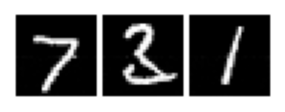

In [ ]:
show_imgs(completed_bottom)

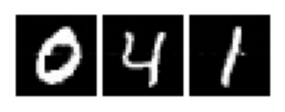

In [ ]:
show_imgs(completed_top)

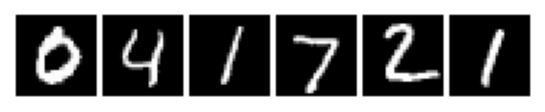

In [ ]:
# get 6 random images
images = images[torch.randperm(len(images))[:6]]
show_imgs(images)

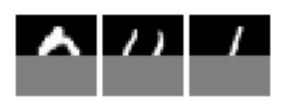

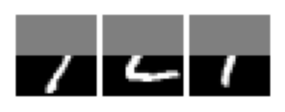

In [ ]:
# plot the visible halves
bottom_mask = create_half_mask(images[:3], mode='bottom')

# masked images
show_imgs(images[:3] * bottom_mask)

top_mask = create_half_mask(images[3:], mode='top')
show_imgs(images[3:] * top_mask)

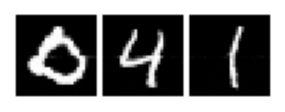

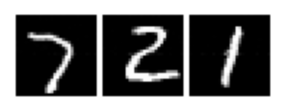

In [ ]:
# Apply mask: y = original * mask
y_bottom = images[:3] * bottom_mask
y_top = images[3:] * top_mask

completed_bottom = complete_image(model,
    y=y_bottom,
    ymask=bottom_mask,
    num_imgs=3
)

completed_top = complete_image(model,
    y=y_top,
    ymask=top_mask,
    num_imgs=3
)

show_imgs(completed_bottom)
show_imgs(completed_top)

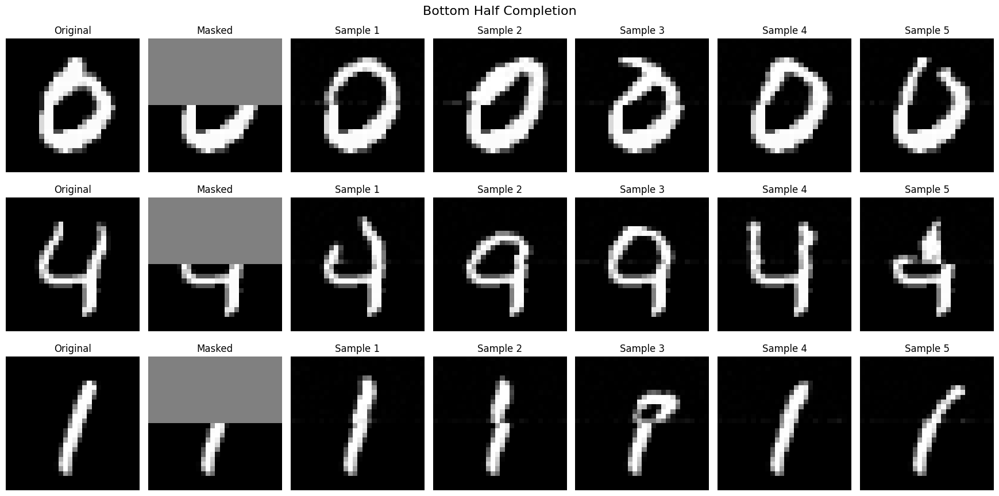

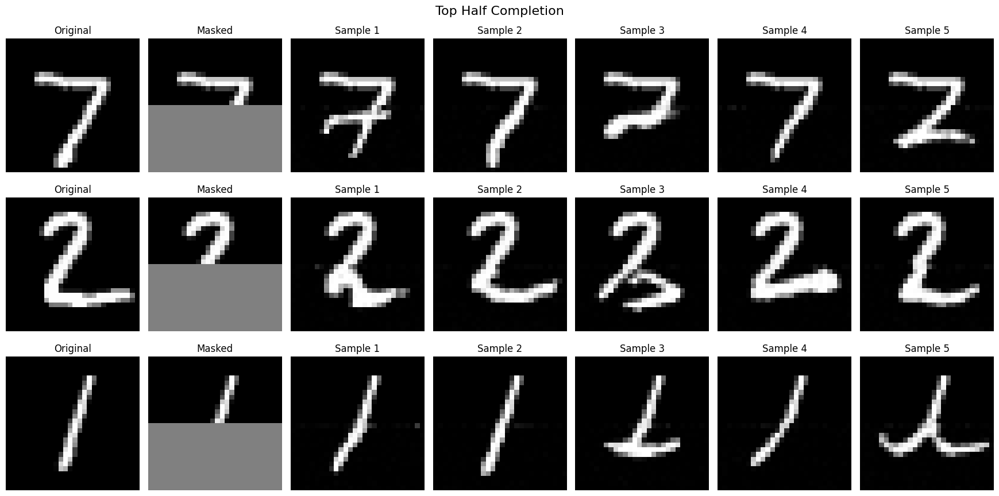

In [ ]:
# Generate 5 completions for each
samples_top = [complete_image(model,y_top, top_mask,3) for _ in range(5)]
samples_bottom = [complete_image(model,y_bottom, bottom_mask,3) for _ in range(5)]

# Plot results
plot_inpainting_results(images[3:], top_mask, samples_top, "Bottom Half Completion")
plot_inpainting_results(images[:3], bottom_mask, samples_bottom, "Top Half Completion")

# Bonus - Adding context
<font color='red'>If you completed the bonus, specify it here.</font><br/>

MNIST is boring! Moreover, what is the point of generating samples without controling them? <br/>
We will use a pretrained CLIP (Contrastive Language-Image Pre-Training).

CLIP creates embeddings of both text and images such that images are aligned to the text that describes them. We will use this to encode text and decode into a new image.

In [ ]:
!pip install --quiet git+https://github.com/openai/CLIP.git

import glob
import csv
from textwrap import wrap

import clip

from PIL import Image
import numpy as np

  Preparing metadata (setup.py) ... done


## Load data
Go to your <a href="https://www.kaggle.com/">Kaggle</a> account and under the settings, generate new API token. <br/>
This will export you a json file, which you will upload here.

In [ ]:
# The script expects you to upload JSON file to it!

! pip install -q kaggle
from google.colab import files
files.upload()
! mkdir ~/.kaggle
! cp kaggle.json ~/.kaggle/
! chmod 600 ~/.kaggle/kaggle.json
! kaggle datasets list
! kaggle datasets download jessicali9530/celeba-dataset
! unzip -q celeba-dataset.zip -d faces

Saving kaggle.json to kaggle (1).json
mkdir: cannot create directory ‘/root/.kaggle’: File exists
ref                                                       title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------  --------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
sahilislam007/college-student-placement-factors-dataset   College Student Placement Factors Dataset               110450  2025-07-02 08:33:50.547000           6028        127  1.0              
abdulmalik1518/cars-datasets-2025                         Cars Datasets (2025)                                     25987  2025-07-17 21:43:28.493000           2607         63  1.0              
urvishahir/electric-vehicle-specifications-dataset-2025   Electric Vehicle Specs Dataset (2025)🔋🚗                  16631  2025

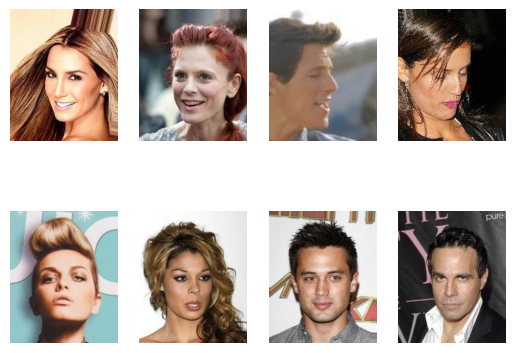

In [ ]:
import matplotlib.pyplot as plt

FACES_PATH = "/content/faces/img_align_celeba/img_align_celeba"

for i in range(1,9):
  img = Image.open(f'{FACES_PATH}/00000{i}.jpg')
  plt.subplot(2, 4, i)
  plt.axis('off')
  plt.imshow(img)

plt.show()

## load pretrained model

In [ ]:
clip.available_models()

['RN50',
 'RN101',
 'RN50x4',
 'RN50x16',
 'RN50x64',
 'ViT-B/32',
 'ViT-B/16',
 'ViT-L/14',
 'ViT-L/14@336px']

In [ ]:
clip_model, clip_preprocess = clip.load("ViT-B/32")
clip_model.eval()
CLIP_FEATURES = 512

## Intro to CLIP

Load image using CLIP

In [ ]:
img = Image.open(f'{FACES_PATH}/000001.jpg')

clip_imgs = torch.tensor(np.stack([clip_preprocess(img)])).to(device)
print("After image clip preprocessing the size is ", clip_imgs.size())

After image clip preprocessing the size is  torch.Size([1, 3, 224, 224])


Feature extractor of CLIP

Now, we want to see how to tokenize text and encoder it using clip

In [ ]:
text_list = [
    "An Angry man",
    "Smiling bald person",
    "Happy beautiful woman"
]
text_tokens = clip.tokenize(text_list).to(device)
print("Text tokens")
print(text_tokens[:,:10])
print("----------------------------")

clip_text_encodings = clip_model.encode_text(text_tokens).float()
print("For each text, encoding of 512 features ", clip_text_encodings.size())
print(clip_text_encodings)

Text tokens
tensor([[49406,   550,  9054,   786, 49407,     0,     0,     0,     0,     0],
        [49406,  9200, 14875,  2533, 49407,     0,     0,     0,     0,     0],
        [49406,   900,  1215,  2308, 49407,     0,     0,     0,     0,     0]],
       device='cuda:0', dtype=torch.int32)
----------------------------
For each text, encoding of 512 features  torch.Size([3, 512])
tensor([[-0.1211,  0.0484,  0.1675,  ..., -0.4663,  0.4883, -0.2671],
        [-0.0769,  0.0007, -0.1137,  ..., -0.1329,  0.0972,  0.0560],
        [ 0.2595,  0.0418, -0.0429,  ..., -0.4988, -0.2382, -0.0294]],
       device='cuda:0', grad_fn=<ToCopyBackward0>)


In order to see which one of our text descriptions best describes the faces, we can calculate the cosine similarity between the text encodings and the image encodings. <br/>
We will load three flowers, give each its encoding and will compare to the texts above

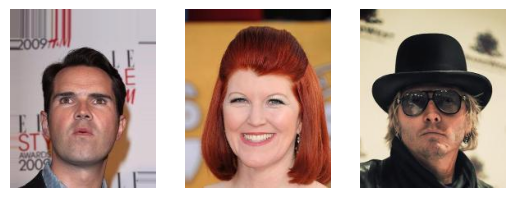

In [ ]:
def get_img_encodings(imgs):
    processed_imgs = [clip_preprocess(img) for img in imgs]
    clip_imgs = torch.tensor(np.stack(processed_imgs)).to(device)
    clip_img_encodings = clip_model.encode_image(clip_imgs)
    return clip_img_encodings

imgs = [Image.open(f"{FACES_PATH}/{i}.jpg") for i in ["000069", "000174", "000154"]]
for i, img in enumerate(imgs):
    plt.subplot(1,3,i+1)
    plt.axis('off')
    plt.imshow(img)

In [ ]:
clip_img_encodings = get_img_encodings(imgs)    # torch.Tensor([3, 512])

text_list = [
    "A surprised man with black hair",
    "A woman smiling with red hair",
    "A person with black glasses and wears black hat"
]

text_tokens = clip.tokenize(text_list).to(device)
clip_text_encodings = clip_model.encode_text(text_tokens)   # torch.Tensor([3, 512])

clip_img_encodings /= clip_img_encodings.norm(dim=-1, keepdim=True)
clip_text_encodings /= clip_text_encodings.norm(dim=-1, keepdim=True)

similarity = clip_img_encodings @ clip_text_encodings.T

print(similarity)

tensor([[0.2708, 0.1172, 0.2247],
        [0.1606, 0.3018, 0.2135],
        [0.1760, 0.0996, 0.3140]], device='cuda:0', dtype=torch.float16,
       grad_fn=<MmBackward0>)


Well, is there a match?

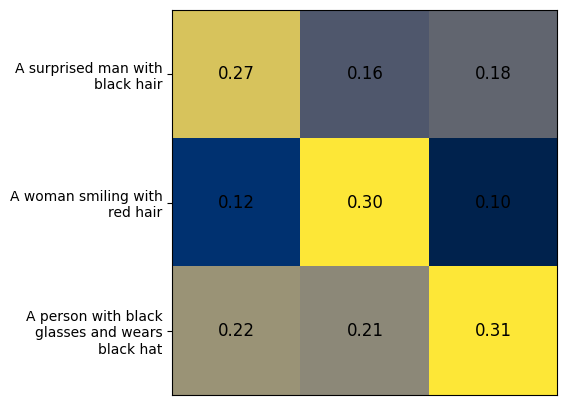

In [ ]:
fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(2, 3, wspace=.1, hspace=0)

ax = fig.add_subplot(gs[1, :])
plt.imshow(similarity.detach().cpu().numpy().T, vmin=0.1, vmax=0.3)

labels = [ '\n'.join(wrap(text, 20)) for text in text_list ]
plt.yticks(range(len(text_tokens)), labels, fontsize=10)
plt.xticks([])

for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[x, y]:.2f}", ha="center", va="center", size=12)

Collabory: CLIP gives the most similar encoding of image to the most similar encoding of text.
Hence, we will train using the image encoding, but create new images using an encoding of text, hopefully it will work

## Proccess the data using clip

In [ ]:
CLIP_FEATURES = 512

def crop_face(sample):
  return sample[:, 9:(9+32),4:(4+32)]

pre_transforms = transforms.Compose([
    transforms.Resize((50, 40)),
    transforms.ToTensor(),  # Scales data into [0,1]
    crop_face,
    transforms.Lambda(lambda t: (t * 2) - 1)  # Scale between [-1, 1]
])

random_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
])

With our current resources, we DO NOT want to encode ~50000 images. Download the csv file. It contains the file paths, along with its preprocessed CLIP data.

Remark: the file contains 202k images. Training on all of them is an excellent idea - example will be attached at the end

In [ ]:
!wget https://srworkspace.com/sharon/dgm/clip_data.zip
!unzip -q clip_data.zip

--2025-07-23 09:36:25--  https://srworkspace.com/sharon/dgm/clip_data.zip
Resolving srworkspace.com (srworkspace.com)... 145.223.107.29, 2a02:4780:b:1104:0:c79:e7e:2
Connecting to srworkspace.com (srworkspace.com)|145.223.107.29|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 344697039 (329M) [application/zip]
Saving to: ‘clip_data.zip’

clip_data.zip       100%[===================>] 328.73M  4.20MB/s    in 79s     

2025-07-23 09:37:45 (4.15 MB/s) - ‘clip_data.zip’ saved [344697039/344697039]



In [ ]:
import glob
import csv
from torch.utils.data import Dataset

class MyDataset(Dataset):
    def __init__(self, csv_path='clip_data.csv', max_samples=50_000):
        self.imgs = []
        self.labels = torch.empty(
            max_samples, CLIP_FEATURES, dtype=torch.float, device=device
        )

        with open(csv_path, newline='') as csvfile:
            reader = csv.reader(csvfile, delimiter=',')
            for idx, row in tqdm(enumerate(reader), total=max_samples):
                if idx >= max_samples:
                    break
                img = Image.open(row[0])
                self.imgs.append(pre_transforms(img).to(device))
                label = [float(x) for x in row[1:]]
                self.labels[idx, :] = torch.FloatTensor(label).to(device)

    def __getitem__(self, idx):
        return random_transforms(self.imgs[idx]), self.labels[idx]

    def __len__(self):
        return len(self.imgs)

data_paths = glob.glob(f'{FACES_PATH}/*.jpg', recursive=True)
faces_data = MyDataset()
faces_dataloader = data.DataLoader(faces_data, batch_size=128, shuffle=True, drop_last=True)

  0%|          | 0/50000 [00:00<?, ?it/s]

In [ ]:
# get first image
img = faces_data[0][0]
print(img.size())

torch.Size([3, 32, 32])


In [ ]:
imgs, clip_desc = next(iter(faces_dataloader))
print(imgs.size())
print(clip_desc.size())

torch.Size([128, 3, 32, 32])
torch.Size([128, 512])


In [ ]:
#@title Components of UNet
import math

class GELUConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, group_size):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, 3, 1, 1),
            nn.GroupNorm(group_size, out_ch),
            nn.GELU(),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class RearrangePoolBlock(nn.Module):
    def __init__(self, in_chs, group_size):
        super().__init__()
        self.rearrange = nn.MaxPool2d(2)
        self.conv = GELUConvBlock(in_chs, in_chs, group_size)

    def forward(self, x):
        x = self.rearrange(x)
        return self.conv(x)


class DownBlock(nn.Module):
    def __init__(self, in_chs, out_chs, group_size):
        super(DownBlock, self).__init__()
        layers = [
            GELUConvBlock(in_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
            RearrangePoolBlock(out_chs, group_size),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class UpBlock(nn.Module):
    def __init__(self, in_chs, out_chs, group_size):
        super(UpBlock, self).__init__()
        layers = [
            nn.ConvTranspose2d(2 * in_chs, out_chs, 2, 2),
            GELUConvBlock(out_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = torch.cat((x, skip), 1)
        x = self.model(x)
        return x


class SinusoidalPositionEmbedBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings


class EmbedBlock(nn.Module):
    def __init__(self, input_dim, emb_dim):
        super(EmbedBlock, self).__init__()
        self.input_dim = input_dim
        layers = [
            nn.Linear(input_dim, emb_dim),
            nn.GELU(),
            nn.Linear(emb_dim, emb_dim),
            nn.Unflatten(1, (emb_dim, 1, 1)),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(-1, self.input_dim)
        return self.model(x)


class ResidualConvBlock(nn.Module):
    def __init__(self, in_chs, out_chs, group_size):
        super().__init__()
        self.conv1 = GELUConvBlock(in_chs, out_chs, group_size)
        self.conv2 = GELUConvBlock(out_chs, out_chs, group_size)

    def forward(self, x):
        x1 = self.conv1(x)
        x2 = self.conv2(x1)
        out = x1 + x2
        return out

## Recap to guidance

So far, the models have generated image without control, but if we somehow embed what we want into the model, it will be taken into account during training!

We use CLIP to encode text into embedding. Then, we will **not** feed it directly to the model, but rather apply a "dropout" on it first, as it will maintain divergence and prevent overfitting (see ```get_context_mask``` later).

Then, at sampling, when removing noise, we will predict two types of noise:
- "keep context" (uses context mask with $p=0$)
- "remove context" (uses context mask with $p=1$)

As always, there is tradeoff, weigted over both noises using
$$
ɛ_t=ɛ_θ(x_t,c=1) \times (1+s)-ɛ_θ(x_t,c=0)\times s
$$

Here is an example for impact of $s$, when we ignore the $\text{keep}\times 1$:

<img width="50%" src="https://srworkspace.com/sharon/dgm/guidance.png"/>


## Modify the model

<img width="70%" src="https://sharon.srworkspace.com/dgm/context1.png"/>

In [ ]:
class UNet(nn.Module):
    def __init__(self, T, img_shape):
        super(UNet, self).__init__()
        img_chs = img_shape[0]
        self.T = T
        down_chs = (32, 64, 128)
        up_chs = down_chs[::-1]  # Reverse of the down channels
        # Calculate latent_image_size based on the input image height and the downsampling factors
        latent_image_size = img_shape[1] // (2 ** (len(down_chs)-1)) # Corrected calculation
        t_embed_dim = 16
        c_embed_dim=CLIP_FEATURES # New

        small_group_size = 8 # New
        big_group_size = 32 # New

        # Inital convolution
        self.down0 = ResidualConvBlock(img_chs, down_chs[0], small_group_size)

        # Downsample
        self.down1 = DownBlock(down_chs[0], down_chs[1], big_group_size)
        self.down2 = DownBlock(down_chs[1], down_chs[2], big_group_size)
        self.to_vec = nn.Sequential(nn.Flatten(), nn.GELU())

        # Embeddings
        self.dense_emb = nn.Sequential(
            nn.Linear(down_chs[2] * latent_image_size**2, down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[2] * latent_image_size**2),
            nn.ReLU(),
        )
        self.sinusoidaltime = SinusoidalPositionEmbedBlock(t_embed_dim)
        self.temb_1 = EmbedBlock(t_embed_dim, up_chs[0])
        self.temb_2 = EmbedBlock(t_embed_dim, up_chs[1])
        self.c_embed1 = EmbedBlock(c_embed_dim, up_chs[0])
        self.c_embed2 = EmbedBlock(c_embed_dim, up_chs[1])

        # Upsample
        self.up0 = nn.Sequential(
            nn.Unflatten(1, (up_chs[0], latent_image_size, latent_image_size)),
            GELUConvBlock(up_chs[0], up_chs[0], big_group_size),
        )
        self.up1 = UpBlock(up_chs[0], up_chs[1], big_group_size)
        self.up2 = UpBlock(up_chs[1], up_chs[2], big_group_size)

        # Match output channels and one last concatenation
        self.out = nn.Sequential(
            nn.Conv2d(2 * up_chs[-1], up_chs[-1], 3, 1, 1),
            nn.GroupNorm(small_group_size, up_chs[-1]),
            nn.ReLU(),
            nn.Conv2d(up_chs[-1], img_chs, 3, 1, 1),
        )

    def forward(self, x, t, c, c_mask):
        # Convert t to range [0,1] and get time embedding
        t_emb = self.sinusoidaltime(t)
        temb1 = self.temb_1(t_emb)
        temb2 = self.temb_2(t_emb)


        # Apply context mask and get context embedding
        c = c * c_mask[:, None]
        cemb1 = self.c_embed1(c)
        cemb2 = self.c_embed2(c)


        # Downsample
        d0 = self.down0(x)
        d1 = self.down1(d0)
        d2 = self.down2(d1)

        # Latent space
        v = self.to_vec(d2)
        v = self.dense_emb(v)

        u0 = self.up0(v)  # Latent + time + context at deepest level
        u0 = u0 + temb1 + cemb1

        # Up1: skip connection from d1 + time + context
        u1 = self.up1(u0, d2)
        u1 = u1 + temb2 + cemb2

        # Up2: skip connection from d0 only (no time/context at this stage)
        u2 = self.up2(u1, d1)

        # Output projection
        out = self.out(torch.cat((u2, d0), 1))
        return out

In [ ]:
class DDPM(nn.Module):
    def __init__(self, T, img_shape, method='cosine'):
        super(DDPM, self).__init__()
        self.T = T

        epsilon=0.008
        if method == 'cosine':
            steps=torch.linspace(0,T,steps=T+1).to(device)
            f_t=torch.cos(((steps/T+epsilon)/(1.0+epsilon))*math.pi*0.5)**2
            self.Beta = torch.clip(1.0-f_t[1:]/f_t[:T], 0.0, 0.999)

        elif method == 'linear':
            self.Beta = torch.linspace(1e-4, 2e-2, T).to(device)

        # Forward diffusion variables
        self.a = 1.0 - self.Beta
        self.a_bar = torch.cumprod(self.a, dim=0)

        self.img_chs = img_shape[0]
        self.img_size = img_shape[1]

        self.net = UNet(T, img_shape)

        # Logging
        self.logs = defaultdict(list)

    def log(self, key, value):
        self.logs[key].append(value)

    def q(self, x_0, t):
        """
        Samples a new image from q
        Returns a tuple (img_after_noise, noise) at timestep t
        x_0: the original image
        t: timestep
        """
        noise = torch.randn_like(x_0).to(device)
        a_bar_t = self.a_bar[t].view(-1, 1, 1, 1)
        x_t = torch.sqrt(a_bar_t) * x_0 + torch.sqrt(1 - a_bar_t) * noise
        return x_t, noise

    @torch.no_grad()
    def reverse_q(self, x_t, t, e_t):
        """
        Samples a new image from p
        Returns a tuple (img_before_noise) at timestep t
        x_t: the noisy image
        t: timestep
        e_t: predicted noise
        """
        a_t = self.a[t].view(-1, 1, 1, 1)
        a_bar_t = self.a_bar[t].view(-1, 1, 1, 1)
        b_t = self.Beta[t].view(-1, 1, 1, 1)
        z = torch.randn_like(x_t).to(device) * (t > 0).float().view(-1, 1, 1, 1)

        x_t_minus_1 = (1 / torch.sqrt(a_t)) * (x_t - b_t / torch.sqrt(1 - a_bar_t) * e_t) + torch.sqrt(b_t) * z
        return x_t_minus_1

    def get_context_mask(self, c, drop_prob=0.1):
        batch_size = c.shape[0]
        device = c.device
        # Generate a mask per sample, not per element
        c_mask = torch.bernoulli(torch.full((batch_size,), 1 - drop_prob, device=device))
        return c_mask  # Shape: [batch_size]


    def get_loss(self, x_0, t, c):
        """
        Returns the loss between the true noise and the predicted noise
        x_0: the original image
        t: timestep
        c: clip embeddings
        """
        x_t, noise = self.q(x_0, t)
        c_mask = self.get_context_mask(c)
        e_t = self.net(x_t, t, c, c_mask)
        loss = F.mse_loss(e_t, noise)
        return loss


    @torch.no_grad()
    def sample(self, text_list, s=0.5):
        self.eval()

        # Get CLIP text embeddings
        text_tokens = clip.tokenize(text_list).to(device)
        c = clip_model.encode_text(text_tokens).float()
        c /= c.norm(dim=-1, keepdim=True)

        # Noise to generate images from
        x_t = torch.randn(len(c), self.img_chs, self.img_size, self.img_size).to(device)
        output = []

        for t in tqdm(reversed(range(self.T)), desc="Sampling", total=self.T):
            t_tensor = torch.full((len(c),), t, dtype=torch.long, device=device)

            # Predict noise with context
            c_mask_keep = self.get_context_mask(c, drop_prob=0.)
            e_t_keep = self.net(x_t, t_tensor, c, c_mask_keep)

            # Predict noise without context
            c_mask_remove = self.get_context_mask(c, drop_prob=1.)
            e_t_remove = self.net(x_t, t_tensor, c, c_mask_remove)

            # Guided noise prediction
            e_t = (1 + s) * e_t_keep - s * e_t_remove

            x_t = self.reverse_q(x_t, t_tensor, e_t)
            output.append(x_t.cpu())

        output = torch.stack(output)  # [T, batch, c, h, w]

        # Pick 10 evenly spaced phases
        num_phases = 10
        indices = torch.linspace(0, self.T - 1, steps=num_phases).long()
        return output[indices]


    def training_step(self, imgs, clip_desc):
        t = torch.randint(0, self.T, (len(imgs),), device=device)
        loss = self.get_loss(imgs, t, clip_desc)

        # Log losses
        self.log('train_loss', loss.item())
        return loss

## Train

This text list will be sampled at the end of each epoch, but does not affect the training.

In [ ]:
# Change me
text_list = [
    "A man wearing a white hat",
    "A woman in sun glasses",
    "A man with green hair and a blue shirt",
    "A sad woman with blue eyes"
]

In [ ]:
img_shape = faces_data[0][0].shape
model = DDPM(T=300, img_shape=img_shape, method='linear')
print("Num params: {:,}".format(sum(p.numel() for p in model.parameters())))
model = torch.compile(model.to(device))

optimizer = optim.Adam(model.parameters(), lr=1e-3)
epochs = 50

Num params: 2,111,619


  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 0 | Loss: 0.14126694869154538 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

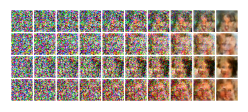

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 1 | Loss: 0.06933148755477025 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

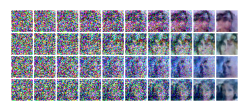

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 2 | Loss: 0.061059217880933714 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

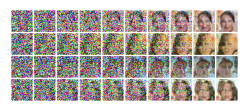

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 3 | Loss: 0.058473891497422485 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

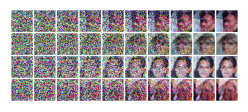

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 4 | Loss: 0.056436150893568994 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

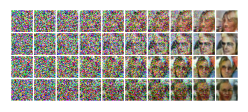

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 5 | Loss: 0.05503385178744793 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

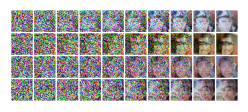

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 6 | Loss: 0.053622528796012585 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

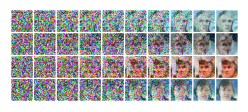

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 7 | Loss: 0.052639450027774544 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

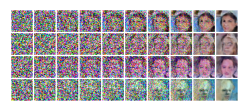

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 8 | Loss: 0.052176038863567205 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

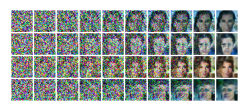

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 9 | Loss: 0.05166955930300248 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

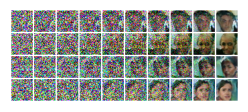

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 10 | Loss: 0.05083666205024108 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

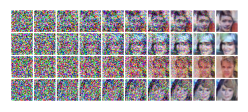

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 11 | Loss: 0.05121414697705171 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

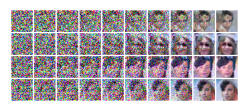

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 12 | Loss: 0.05086292334091969 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

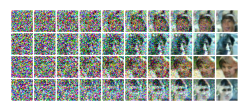

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 13 | Loss: 0.05060922562693938 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

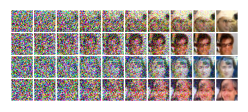

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 14 | Loss: 0.05008546566733947 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

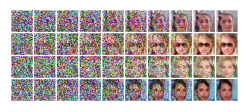

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 15 | Loss: 0.04925918687994663 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

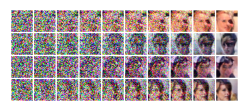

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 16 | Loss: 0.04967375510396101 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

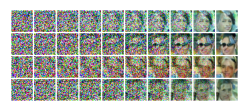

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 17 | Loss: 0.04862360239315491 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

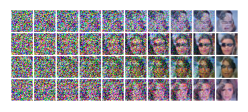

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 18 | Loss: 0.04959506338987595 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

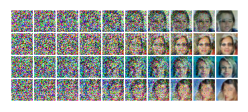

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 19 | Loss: 0.048625496096718006 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

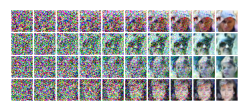

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 20 | Loss: 0.04875723367127088 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

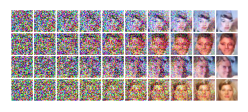

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 21 | Loss: 0.048726011535678154 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

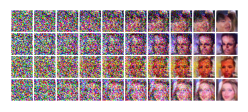

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 22 | Loss: 0.048011833954698 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

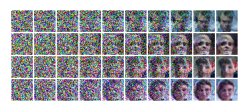

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 23 | Loss: 0.048744522063777995 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

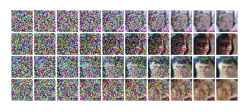

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 24 | Loss: 0.04856621550443845 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

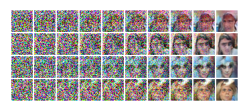

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 25 | Loss: 0.04801671392260454 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

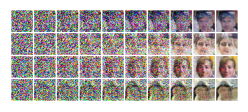

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 26 | Loss: 0.04844325244044646 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

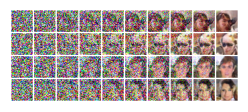

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 27 | Loss: 0.048133816746756056 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

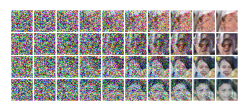

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 28 | Loss: 0.0480466848000502 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

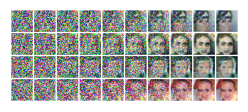

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 29 | Loss: 0.04804119183084904 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

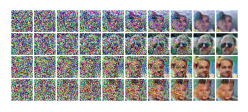

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 30 | Loss: 0.04754889644682407 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

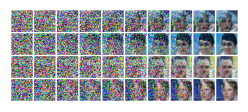

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 31 | Loss: 0.04779488554176612 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

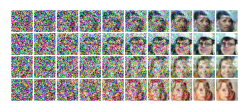

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 32 | Loss: 0.04804177369253758 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

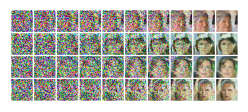

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 33 | Loss: 0.04737798045747555 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

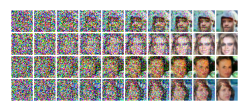

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 34 | Loss: 0.047558753354809226 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

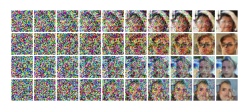

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 35 | Loss: 0.047765890188897264 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

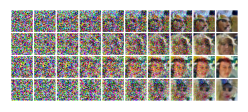

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 36 | Loss: 0.04721944087590927 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

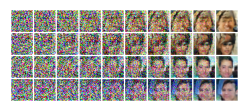

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 37 | Loss: 0.047439125476357265 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

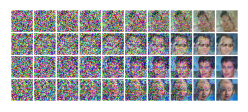

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 38 | Loss: 0.04671698370232032 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

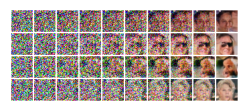

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 39 | Loss: 0.04672222944597403 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

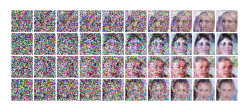

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 40 | Loss: 0.047747562572551076 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

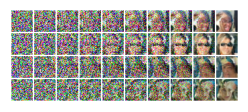

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 41 | Loss: 0.047580190896032715 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

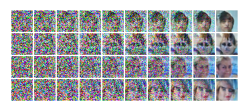

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 42 | Loss: 0.047129233959966745 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

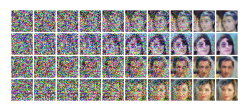

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 43 | Loss: 0.04729830206204683 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

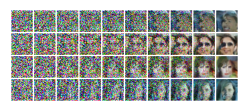

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 44 | Loss: 0.04726650092082146 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

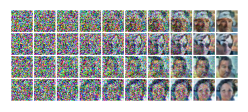

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 45 | Loss: 0.04644276864635639 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

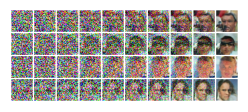

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 46 | Loss: 0.04604560788243245 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

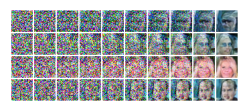

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 47 | Loss: 0.04640478219072788 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

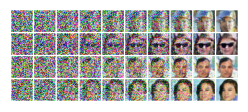

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 48 | Loss: 0.046631117298817026 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

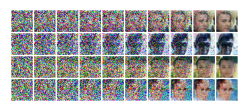

  0%|          | 0/390 [00:00<?, ?it/s]

Epoch 49 | Loss: 0.04675012138218452 


Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

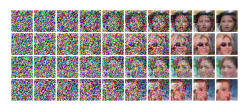

In [ ]:
# Training loop
for epoch in range(epochs):
    model.train()
    losses = []

    for imgs, clip_desc in tqdm(faces_dataloader):
        imgs = imgs.to(device)
        clip_desc = clip_desc.to(device)
        optimizer.zero_grad()
        loss = model.training_step(imgs, clip_desc)
        loss.backward()
        optimizer.step()

    if epoch % 1 == 0:
        epoch_loss = np.mean(model.logs['train_loss'][-390:])
        print(f"Epoch {epoch} | Loss: {epoch_loss} ")
        sampled_data = model.sample(text_list, s=1.)
        show_imgs(sampled_data)

# Save the model
torch.save(model.state_dict(), 'clip_faces.pth')

## Final evaluation

Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

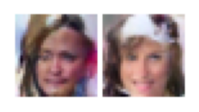

In [ ]:
text_list_new = [
    "A sad man with long hair",
    "A smiling woman with green eyes"
]

sampled_data = model.sample(text_list_new, s=0) # you may change 's'
show_imgs(sampled_data[-1])

In [ ]:
@torch.no_grad()
def sample_unconditional(model, batch_size=16):
    model.eval()

    # Dummy text input for shape compatibility
    dummy_text = [""] * batch_size
    text_tokens = clip.tokenize(dummy_text).to(device)
    c = clip_model.encode_text(text_tokens).float()
    c /= c.norm(dim=-1, keepdim=True)

    # Mask out context completely (drop_prob = 1)
    c_mask_remove = model.get_context_mask(c, drop_prob=1.)

    # Start from pure noise
    x_t = torch.randn(batch_size, model.img_chs, model.img_size, model.img_size).to(device)
    output = []

    for t in tqdm(reversed(range(model.T)), desc="Unconditional Sampling", total=model.T):
        t_tensor = torch.full((batch_size,), t, dtype=torch.long, device=device)
        e_t = model.net(x_t, t_tensor, c, c_mask_remove)
        x_t = model.reverse_q(x_t, t_tensor, e_t)
        output.append(x_t.cpu())

    return x_t  # shape [T, batch, c, h, w]


Unconditional Sampling:   0%|          | 0/300 [00:00<?, ?it/s]

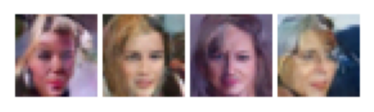

In [ ]:
samples_uncond = sample_unconditional(model, batch_size=4)  # shape [T, 4, c, h, w]
show_imgs(samples_uncond)

As promised, here are samples from a larger model trained over all the images of CelebA

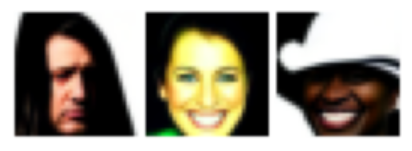

In [ ]:
!pip install my_library